## Melakukan Uji coba testing koneksi Neo4j

In [1]:
import os
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D
from neo4j import GraphDatabase, RoutingControl
from tqdm.auto import tqdm

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "PASSWORD"  
DATABASE = "neo4j"
AUTH = (USER, PASSWORD)

SEED = 42                      
K = 5                           
TOP_N = 5                       
SOURCE_DIR = "data"
CSV_PATH = os.path.join(SOURCE_DIR, "events.csv")
TRAIN_CSV = os.path.join(SOURCE_DIR, "events_P1.csv")   
TEST_CSV = os.path.join(SOURCE_DIR, "events_P2.csv")    

P1_START, P1_END = "2015-05-18", "2015-07-18"   
P2_START, P2_END = "2015-07-27", "2015-08-11"   

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi Neo4j berhasil")


def run_query(query, **params):
    global driver
    try:
        session = driver.session(database=DATABASE)
    except Exception:                      # driver sudah ditutup → buat ulang
        driver = GraphDatabase.driver(URI, auth=AUTH)
        session = driver.session(database=DATABASE)
    with session:
        return [rec.data() for rec in session.run(query, **params)]


def l2_normalize(M):
    norms = np.sqrt(M.multiply(M).sum(axis=1)).A1
    norms[norms == 0] = 1.0
    return (sp.diags(1.0 / norms) @ M).tocsr()

Koneksi Neo4j berhasil


c:\Users\USER\OneDrive\Documents\GSD\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [78]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DATABASE,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name AS friend ORDER BY friend.name",
        name=name, database_=DATABASE, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil")
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. The subclause expression `friend.name` contains an ambiguous reference to variable `friend` and is deprecated. It is replaced by referencing the projection item expression by an alias or using the `GROUP BY` clause.', position=<SummaryInputPosition line=1, column=102, offset=101>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 101, 'line': 1, 'column': 102}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name RETURN friend.name AS friend ORDER BY friend.name'


Koneksi Neo4j berhasil
Guinevere
Lancelot
Merlin


## Soal Pendahuluan

**1 Nama database yang digunakan pada tutorial**

Database yang digunakan adalah `neo4j` (database default, lihat parameter `database_="neo4j"`).

**2. Akses lain untuk mengakses database lain dalam satu instance**

Satu instance dapat menampung lebih dari satu database. Ada empat cara mengaksesnya:
1. **Perintah administrasi (DDL)** pada database `system`, misalnya `CREATE DATABASE tokoonline`, `SHOW DATABASES`, `START DATABASE`, `STOP DATABASE`, `DROP DATABASE`.
2. **`:use tokoonline`** pada Neo4j Browser atau `cypher-shell`, yang mengarahkan seluruh query berikutnya ke database tersebut.
3. **Klausa `USE` di dalam query**, misalnya `USE tokoonline MATCH (n) RETURN n LIMIT 10`, yang memilih database hanya untuk query tersebut.
4. **Python driver**: ubah parameter `database_` pada `execute_query`, atau buka sesi dengan `driver.session(database="tokoonline")`.

Fitur multi-database tidak tersedia pada semua edisi: edisi Community hanya mendukung satu database pengguna.

**3. Jenis graf pertemanan yang telah dibuat**

Graf yang dibuat dari `MERGE (a)-[:KNOWS]->(friend)` adalah **graf berarah** karena relasi memakai tanda panah: Arthur mengenal ketiga temannya, tetapi hubungan sebaliknya tidak otomatis terbentuk. Graf ini **homogen** (hanya satu label simpul `Person` dan satu tipe relasi `KNOWS`) dan **tidak berbobot** (relasi tidak punya properti).

Dari sisi struktur, graf berbentuk **bintang**: Arthur di pusat terhubung ke Guinevere, Lancelot, dan Merlin yang tidak saling terhubung dan tidak membentuk siklus. Penggunaan `MERGE` menjadikannya graf sederhana tanpa simpul/relasi ganda.

## 2.1 Data Wrangling dan EDA

### 1-2 Data Wrangling

In [3]:
required = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_PATH}")

df = pd.read_csv(CSV_PATH)
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Kolom dataset tidak lengkap: {sorted(missing)}")
df = df[["timestamp", "visitorid", "event", "itemid", "transactionid"]]

print("Shape data mentah:", df.shape)
display(df.head())

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "null": df.isna().sum(),
    "null_%": (100 * df.isna().mean()).round(3),
    "unik": df.nunique(),
})
display(audit)

is_tx = df["event"].eq("transaction")
print("Baris duplikat penuh            :", int(df.duplicated().sum()))
print("Transaksi tanpa transactionid   :", int((is_tx & df["transactionid"].isna()).sum()))
print("Non-transaksi ber-transactionid :", int((~is_tx & df["transactionid"].notna()).sum()))
print("\nDistribusi event:")
display(df["event"].value_counts(dropna=False).rename("count").to_frame())

Shape data mentah: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


,dtype,null,null_%,unik
timestamp,int64,0,0.000,2750455
visitorid,int64,0,0.000,1407580
event,str,0,0.000,3
itemid,int64,0,0.000,235061
transactionid,float64,2733644,99.185,17672


Baris duplikat penuh            : 460
Transaksi tanpa transactionid   : 0
Non-transaksi ber-transactionid : 0

Distribusi event:


,count
event,
view,2664312
addtocart,69332
transaction,22457


In [4]:
wrangling_log = []

def log_step(name, before, after):
    wrangling_log.append({"langkah": name, "baris_sebelum": before, "baris_sesudah": after, "dibuang": before - after})

n = len(df)
df = df.dropna(subset=["timestamp", "visitorid", "event", "itemid"])
log_step("1. Buang null pada kolom wajib", n, len(df))

n = len(df)
df["event"] = df["event"].astype(str).str.strip().str.lower()
df = df[df["event"].isin({"view", "addtocart", "transaction"})]
log_step("2. Buang event tidak valid", n, len(df))

df = df.astype({"timestamp": "int64", "visitorid": "int64", "itemid": "int64"})

n = len(df)
df = df[df["timestamp"] > 0]
log_step("3. Buang timestamp tidak valid", n, len(df))

n = len(df)
df = df[~((df["event"] == "transaction") & df["transactionid"].isna())]
df.loc[df["event"] != "transaction", "transactionid"] = np.nan
log_step("4. Buang transaksi tanpa transactionid", n, len(df))

n = len(df)
df = df.drop_duplicates()
log_step("5. Buang duplikat penuh", n, len(df))

df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
df = df.sort_values(["timestamp", "visitorid", "itemid"], kind="stable").reset_index(drop=True)
print("Rentang waktu:", df["datetime"].min(), "s.d.", df["datetime"].max())
display(pd.DataFrame(wrangling_log))

Rentang waktu: 2015-05-03 03:00:04.384000+00:00 s.d. 2015-09-18 02:59:47.788000+00:00


,langkah,baris_sebelum,baris_sesudah,dibuang
0,1. Buang null pada kolom wajib,2756101,2756101,0
1,2. Buang event tidak valid,2756101,2756101,0
2,3. Buang timestamp tidak valid,2756101,2756101,0
3,4. Buang transaksi tanpa transactionid,2756101,2756101,0
4,5. Buang duplikat penuh,2756101,2755641,460


Tersimpan: data\events_P1.csv dan data\events_P2.csv

TRAIN/P1: rows=1,296,636, visitors=666,575, items=170,524


,count
event,
view,1254757
addtocart,31460
transaction,10419



TEST/P2: rows=309,451, visitors=175,001, items=83,315


,count
event,
view,298497
addtocart,8279
transaction,2675



Visitor P2 yang ada di P1: 10,552 dari 175,001 (6.0%)
Item P2 yang ada di P1   : 65,605 dari 83,315 (78.7%)


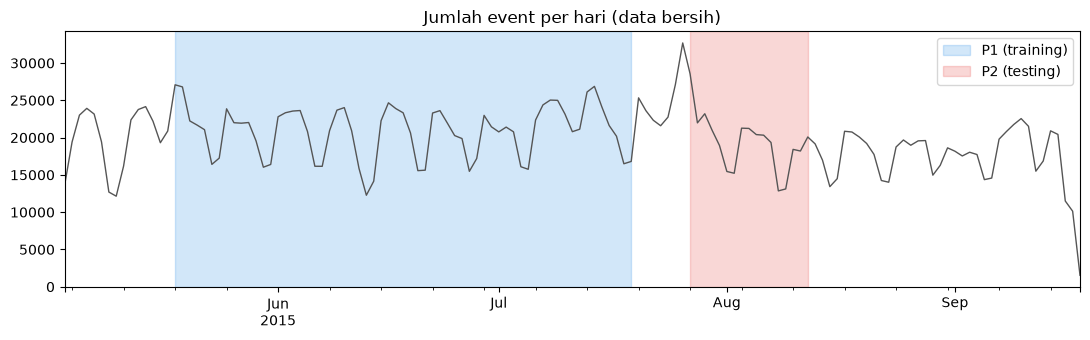

In [5]:
def filter_period(data, start, end):
    lo = pd.Timestamp(start, tz="UTC")
    hi = pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)       
    return data.loc[(data["datetime"] >= lo) & (data["datetime"] < hi)].copy()


def save_period(frame, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    out = frame[["timestamp", "visitorid", "event", "itemid", "transactionid"]].copy()
    out["transactionid"] = out["transactionid"].astype("Int64")   
    out.to_csv(path, index=False)

assert pd.Timestamp(P1_END) < pd.Timestamp(P2_START), "Periode P1 dan P2 tidak boleh tumpang tindih"
train = filter_period(df, P1_START, P1_END)
test = filter_period(df, P2_START, P2_END)
save_period(train, TRAIN_CSV)
save_period(test, TEST_CSV)
print("Tersimpan:", TRAIN_CSV, "dan", TEST_CSV)

for label, frame in [("TRAIN/P1", train), ("TEST/P2", test)]:
    print(f"\n{label}: rows={len(frame):,}, visitors={frame.visitorid.nunique():,}, items={frame.itemid.nunique():,}")
    display(frame["event"].value_counts().rename("count").to_frame())

# Irisan P1-P2 (seberapa banyak user/item P2 yang sudah dikenal di P1 → gambaran cold-start)
v_tr, v_te = set(train.visitorid), set(test.visitorid)
i_tr, i_te = set(train.itemid), set(test.itemid)
print(f"\nVisitor P2 yang ada di P1: {len(v_tr & v_te):,} dari {len(v_te):,} ({100*len(v_tr & v_te)/len(v_te):.1f}%)")
print(f"Item P2 yang ada di P1   : {len(i_tr & i_te):,} dari {len(i_te):,} ({100*len(i_tr & i_te)/len(i_te):.1f}%)")

# Aktivitas harian dan posisi P1/P2
daily = df.set_index("datetime").resample("D").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
daily.plot(ax=ax, color="#555", lw=1)
for (a, b), color, lab in [((P1_START, P1_END), "#1e88e5", "P1 (training)"), ((P2_START, P2_END), "#e53935", "P2 (testing)")]:
    ax.axvspan(pd.Timestamp(a, tz="UTC"), pd.Timestamp(b, tz="UTC") + pd.Timedelta(days=1), color=color, alpha=0.2, label=lab)
ax.set_title("Jumlah event per hari (data bersih)"); ax.set_xlabel(""); ax.legend(); plt.tight_layout(); plt.show()

### Penjelasan 2.1 No. 1-2: Komposisi Subgraf dan Query Cypher
- **P1 (training):** 18/05/2015 – 18/07/2015, disimpan di `data/data_train/events.csv`
- **P2 (testing):** 27/07/2015 – 11/08/2015, disimpan di `data/data_test/events.csv`

Filter diterapkan pada kolom `timestamp` (epoch milidetik → UTC) sebelum data diimpor. Hanya P1 yang diimpor ke Neo4j (membentuk subgraf); P2 dipakai sebagai kebenaran dasar evaluasi pada 2.2.

### Import P1 ke neo4j

In [ ]:
BATCH_SIZE = 5000

IMPORT_CYPHER = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL (v, i, row) {
  WITH v, i, row WHERE row.event = 'view'
  CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
  UNION ALL
  WITH v, i, row WHERE row.event = 'addtocart'
  CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
  UNION ALL
  WITH v, i, row WHERE row.event = 'transaction'
  CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
"""


def import_batch(tx, batch):
    tx.run(IMPORT_CYPHER, batch=batch)


def graph_counts():
    rel = run_query("MATCH (:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item) RETURN count(r) AS n")[0]["n"]
    vis = run_query("MATCH (v:Visitor) RETURN count(v) AS n")[0]["n"]
    itm = run_query("MATCH (i:Item) RETURN count(i) AS n")[0]["n"]
    return {"relasi": int(rel), "visitor": int(vis), "item": int(itm)}

expected_state = {"relasi": len(train), "visitor": int(train.visitorid.nunique()), "item": int(train.itemid.nunique())}
print("Keadaan graf yang diharapkan:", expected_state)


def reset_graph():
    run_query("MATCH (n) WHERE n:Visitor OR n:Item "
              "CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS")


current = graph_counts()
if current == expected_state:
    print("Graf P1 sudah sesuai CSV — impor dilewati.", current)
else:
    print("Graf tidak sesuai CSV:", current, "vs", expected_state, "→ reset lalu impor ulang.")
    reset_graph()
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
    n_chunks = -(-len(train) // BATCH_SIZE)
    reader = pd.read_csv(TRAIN_CSV, chunksize=BATCH_SIZE, dtype={"transactionid": "string"})
    with driver.session(database=DATABASE) as session:
        for chunk in tqdm(reader, total=n_chunks, desc="Impor P1 ke Neo4j"):
            chunk["transactionid"] = chunk["transactionid"].fillna("")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    current = graph_counts()
    assert current == expected_state, f"Impor tidak sesuai CSV: {current} vs {expected_state}"
    print("Impor selesai dan terverifikasi:", current)

Keadaan graf yang diharapkan: {'relasi': 1296636, 'visitor': 666575, 'item': 170524}
Graf P1 sudah sesuai CSV — impor dilewati. {'relasi': 1296636, 'visitor': 666575, 'item': 170524}


### 3. Komposisi subgraf

In [7]:
q_nodes = """MATCH (n) WHERE n:Visitor OR n:Item
RETURN labels(n) AS label, count(n) AS jumlah ORDER BY jumlah DESC"""
q_rels = """MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY jumlah DESC"""
q_pattern = """MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(r) AS jumlah_relasi,
       count(DISTINCT v) AS visitor_unik, count(DISTINCT i) AS item_unik
ORDER BY jumlah_relasi DESC"""

df_nodes = pd.DataFrame(run_query(q_nodes))
df_nodes["label"] = df_nodes["label"].apply(lambda labels: ", ".join(labels))
df_rels = pd.DataFrame(run_query(q_rels))
df_pattern = pd.DataFrame(run_query(q_pattern))
print("Jenis simpul:"); display(df_nodes)
print("Jenis relasi:"); display(df_rels)
print("Rincian pola Visitor-Item:"); display(df_pattern)

# Verifikasi terhadap CSV P1
node_counts = df_nodes.set_index("label")["jumlah"].to_dict()
assert node_counts["Visitor"] == train.visitorid.nunique()
assert node_counts["Item"] == train.itemid.nunique()
assert int(df_rels["jumlah"].sum()) == len(train)
print("✔ Komposisi graf sama dengan CSV P1.")

Jenis simpul:


,label,jumlah
0,Visitor,666575
1,Item,170524


Jenis relasi:


,relasi,jumlah
0,VIEWED,1254757
1,ADDED_TO_CART,31460
2,BOUGHT,10419


Rincian pola Visitor-Item:


,relasi,jumlah_relasi,visitor_unik,item_unik
0,VIEWED,1254757,665193,170365
1,ADDED_TO_CART,31460,17399,14046
2,BOUGHT,10419,5488,6622


✔ Komposisi graf sama dengan CSV P1.


Komposisi subgraf diperoleh menggunakan Python API dengan menjalankan query Cypher melalui fungsi `run_query()`, kemudian hasilnya diubah menjadi DataFrame agar mudah dianalisis.

Untuk mengetahui jenis simpul dan jumlah masing-masing simpul, digunakan query Cypher berikut:

```
MATCH (n)
WHERE n:Visitor OR n:Item
RETURN labels(n) AS label, count(n) AS jumlah
ORDER BY jumlah DESC
```

Query `MATCH (n)` digunakan untuk mencocokkan simpul dalam graf. Kondisi `WHERE n:Visitor OR n:Item` membatasi simpul yang dihitung hanya pada label `Visitor` dan `Item`. Fungsi `labels(n)` menampilkan jenis simpul, sedangkan `count(n)` menghitung jumlah simpul untuk setiap label. Hasilnya diurutkan berdasarkan jumlah simpul dari terbesar ke terkecil.

Hasil query menunjukkan bahwa terdapat 666.575 simpul `Visitor` dan 170.524 simpul `Item`, sehingga totalnya adalah 837.099 simpul.

Untuk mengetahui jenis relasi dan jumlah masing-masing relasi, digunakan query Cypher berikut:

```
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(r) AS jumlah
ORDER BY jumlah DESC
```

Query tersebut mencocokkan relasi berarah dari `Visitor` ke `Item`. Fungsi `type(r)` digunakan untuk mengetahui jenis relasi, sedangkan `count(r)` menghitung jumlah setiap jenis relasi. Hasilnya menunjukkan terdapat 1.254.757 relasi `VIEWED`, 31.460 relasi `ADDED_TO_CART`, dan 10.419 relasi `BOUGHT`, dengan total 1.296.636 relasi.

Berdasarkan hasil tersebut, subgraf termasuk graf bipartit, berarah, dan heterogen karena memiliki dua jenis simpul, yaitu `Visitor` dan `Item`, serta tiga jenis relasi yang menghubungkan keduanya. Relasi didominasi oleh aktivitas melihat produk (`VIEWED`), sedangkan aktivitas pembelian (`BOUGHT`) memiliki jumlah paling sedikit. Hasil perhitungan juga diverifikasi menggunakan `assert` untuk memastikan jumlah simpul dan relasi sesuai dengan data CSV P1.

### VSM 

In [ ]:
# ===== Parameter =====
N_SAMPLE        = 100   
N_SAMPLE_COSINE = 500   
N_PLOT_NODES    = 30    
TOP_K           = 3     

q_edges = """MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN DISTINCT v.visitorId AS visitor, i.itemId AS item"""
agg = pd.DataFrame(run_query(q_edges))
if agg.empty:
    raise RuntimeError("Tidak ada relasi P1 di Neo4j. Periksa langkah impor.")

u_codes, visitor_ids = pd.factorize(agg["visitor"], sort=True)   
i_codes, item_ids = pd.factorize(agg["item"], sort=True)        
UI = sp.csr_matrix((np.ones(len(agg), dtype=np.float32), (u_codes, i_codes)),
                   shape=(len(visitor_ids), len(item_ids)))      
Mu = UI.tocsr()        
Mi = UI.T.tocsr()      
print("M_u (user × item):", Mu.shape, "nnz =", Mu.nnz)
print("M_i (item × user):", Mi.shape, "nnz =", Mi.nnz)


def describe_matrix(M, name):
    row_nnz = np.diff(M.indptr)
    return {
        "Proyeksi": name,
        "Jumlah vektor": M.shape[0],
        "Dimensi vektor": M.shape[1],
        "Shape": f"{M.shape[0]} × {M.shape[1]}",
        "nnz": M.nnz,
        "Density": M.nnz / (M.shape[0] * M.shape[1]),
        "Rata-rata nnz/vektor": row_nnz.mean(),
        "Median nnz/vektor": float(np.median(row_nnz)),
        "Maks nnz/vektor": int(row_nnz.max()),
        "Memori sparse (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "Memori dense float32 (GB)": M.shape[0] * M.shape[1] * 4 / 1e9,
    }

def sample_similarity_stats(M, sample=N_SAMPLE_COSINE, seed=SEED):
    Mn = l2_normalize(M)
    idx = np.random.default_rng(seed).choice(Mn.shape[0], size=min(sample, Mn.shape[0]), replace=False)
    t0 = time.perf_counter()
    S = (Mn[idx] @ Mn.T).tocsr()
    elapsed = time.perf_counter() - t0
    counts = np.diff(S.indptr) - 1     
    return elapsed, counts


def profile_matrix(M, name):
    info = describe_matrix(M, name)
    elapsed, counts = sample_similarity_stats(M)
    info["Waktu cosine sampel (s)"] = elapsed
    info["Rata-rata tetangga sampel"] = counts.mean()
    info["% sampel punya tetangga"] = 100 * (counts > 0).mean()
    return info


def projection_stats(M, name, n=N_SAMPLE):
    chosen = np.argsort(-np.diff(M.indptr), kind="stable")[:n]
    t0 = time.perf_counter()
    Mn = l2_normalize(M[chosen])
    S = sp.triu((Mn @ Mn.T).tocsr(), k=1).tocsr()
    S.eliminate_zeros()
    elapsed = time.perf_counter() - t0
    n_node, n_edge = len(chosen), S.nnz
    return {
        "Proyeksi": name,
        "Jumlah simpul": n_node,
        "Jumlah edge": n_edge,
        "Kepadatan graf": n_edge / (n_node * (n_node - 1) / 2),
        "Rata-rata derajat": 2 * n_edge / n_node,
        "Waktu (detik)": elapsed,
    }

def plot_projection(M, labels, title, n_nodes=N_PLOT_NODES, top_k=TOP_K, seed=SEED):
    chosen = np.argsort(-np.diff(M.indptr), kind="stable")[:min(n_nodes, M.shape[0])]
    normalized = l2_normalize(M[chosen])
    S = (normalized @ normalized.T).toarray()
    np.fill_diagonal(S, 0)
    G = nx.Graph()
    for original_idx in chosen:
        G.add_node(str(labels[original_idx]))
    for a in range(len(chosen)):
        for b in np.argsort(-S[a])[:top_k]:
            if S[a, b] > 0:
                G.add_edge(str(labels[chosen[a]]), str(labels[chosen[b]]), weight=float(S[a, b]))
    pos = nx.spring_layout(G, seed=seed, weight="weight")
    widths = [1 + 3 * G[u][v]["weight"] for u, v in G.edges()]
    plt.figure(figsize=(10, 7))
    nx.draw_networkx(G, pos, node_size=280, font_size=7, width=widths, alpha=0.85)
    plt.title(f"{title} — sampel {len(chosen)} vektor terpadat, top-{top_k} tetangga")
    plt.axis("off"); plt.show()

M_u (user × item): (666575, 170524) nnz = 1006884
M_i (item × user): (170524, 666575) nnz = 1006884


### 4. VSM User

,VSM User
Jumlah vektor,666575
Dimensi vektor,170524
Shape,666575 × 170524
nnz,1006884
Density,0.000009
Rata-rata nnz/vektor,1.510534
Median nnz/vektor,1.0
Maks nnz/vektor,1937
Memori sparse (MB),10.721376
Memori dense float32 (GB),454.668141


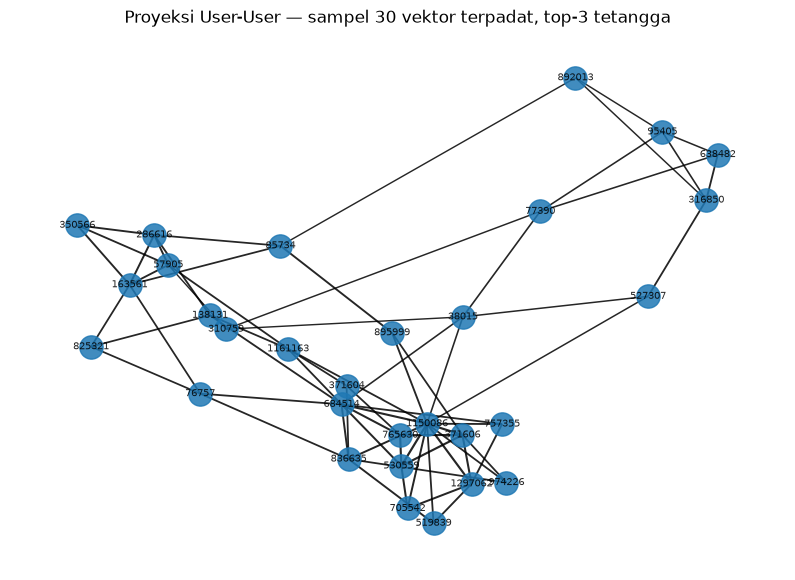

In [33]:
info_user = profile_matrix(Mu, "User")
display(pd.Series(info_user).drop("Proyeksi").to_frame("VSM User"))
plot_projection(Mu, visitor_ids, "Proyeksi User-User")

### Penjelasan 2.1 No. 4: Penjelasan Hasil VSM User

Vector Space Modelling (VSM) diterapkan pada 666.575 simpul `Visitor`, dengan setiap user direpresentasikan sebagai vektor dan setiap dimensi mewakili satu dari 170.524 item. Matriks yang dihasilkan memiliki shape 666.575 × 170.524, dengan 1.006.884 elemen nonnol (nnz) dan density sebesar 0,000009. Hal ini menunjukkan bahwa matriks sangat sparse, sehingga penggunaan format sparse lebih efisien dari segi memori dibandingkan format dense.

Kemiripan antar-user dihitung menggunakan cosine similarity, dengan waktu perhitungan sampel sebesar 0,031881 detik. Hasilnya menunjukkan rata-rata 71,18 tetangga per user sampel, dan 94,8% sampel memiliki tetangga.

Pada visualisasi NetworkX, simpul merepresentasikan user, sedangkan garis menunjukkan hubungan dengan tetangga terdekat berdasarkan kemiripan vektor. Visualisasi menggunakan sampel 30 vektor terpadat dengan konfigurasi top-3 tetangga untuk memperlihatkan pola hubungan antar-user.

### 5. VSM Item

,VSM Item
Jumlah vektor,170524
Dimensi vektor,666575
Shape,170524 × 666575
nnz,1006884
Density,0.000009
Rata-rata nnz/vektor,5.904647
Median nnz/vektor,2.0
Maks nnz/vektor,1553
Memori sparse (MB),8.737172
Memori dense float32 (GB),454.668141


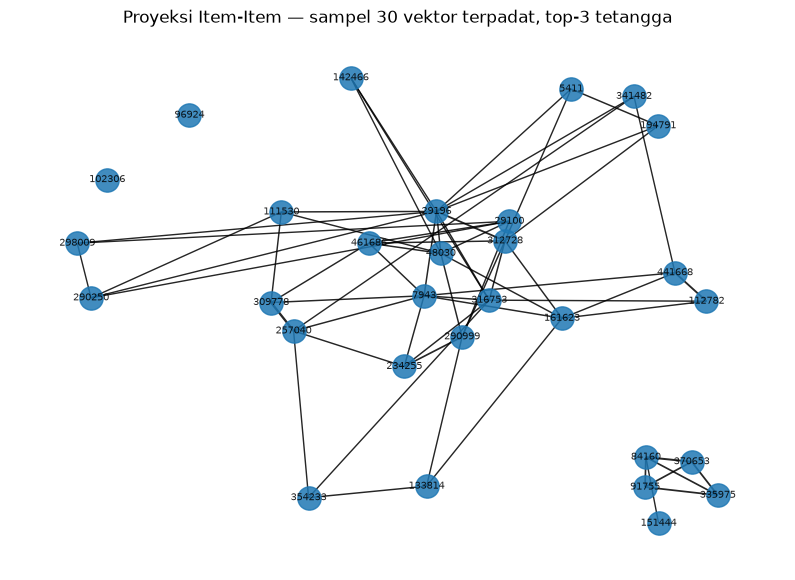

In [34]:
info_item = profile_matrix(Mi, "Item")
display(pd.Series(info_item).drop("Proyeksi").to_frame("VSM Item"))
plot_projection(Mi, item_ids, "Proyeksi Item-Item")

### Penjelasan 2.1 No. 5: Penjelasan Hasil VSM Item

Vector Space Modelling (VSM) diterapkan pada 170.524 simpul Item, dengan setiap item direpresentasikan sebagai vektor dan setiap dimensi mewakili satu dari 666.575 user. Matriks yang dihasilkan memiliki shape 170.524 × 666.575, dengan 1.006.884 elemen nonnol (nnz) dan density sebesar 0,000009. Hal ini menunjukkan bahwa matriks sangat sparse, sehingga format sparse lebih efisien dalam penggunaan memori.

Kemiripan antar-item dihitung menggunakan cosine similarity, dengan waktu perhitungan sampel sebesar 0,02791 detik. Hasilnya menunjukkan rata-rata 127,53 tetangga per item sampel, sedangkan 62,2% sampel memiliki tetangga.

Pada visualisasi NetworkX, simpul merepresentasikan item, sedangkan garis menunjukkan hubungan dengan tetangga terdekat berdasarkan kemiripan vektor. Visualisasi menggunakan sampel 30 vektor item terpadat dengan konfigurasi top-3 tetangga untuk menggambarkan pola kemiripan antar-item berdasarkan interaksi user.

### 6. Perbandingan VSM User dan VSM Item

In [ ]:
cmp_df = pd.DataFrame([info_user, info_item]).set_index("Proyeksi")
display(cmp_df.T)

tabel_proyeksi = pd.DataFrame([projection_stats(Mu, "User"), projection_stats(Mi, "Item")])
display(tabel_proyeksi.round({"Kepadatan graf": 5, "Rata-rata derajat": 2, "Waktu (detik)": 5}))

Proyeksi,User,Item
Jumlah vektor,666575,170524
Dimensi vektor,170524,666575
Shape,666575 × 170524,170524 × 666575
nnz,1006884,1006884
Density,0.000009,0.000009
Rata-rata nnz/vektor,1.510534,5.904647
Median nnz/vektor,1.0,2.0
Maks nnz/vektor,1937,1553
Memori sparse (MB),10.721376,8.737172
Memori dense float32 (GB),454.668141,454.668141


,Proyeksi,Jumlah simpul,Jumlah edge,Kepadatan graf,Rata-rata derajat,Waktu (detik)
0,User,100,4008,0.80970,80.16,0.00420
1,Item,100,2000,0.40404,40.00,0.01022


### Penjelasan 2.1 No. 6: Penjelasan Perbandingan VSM User dan VSM Item

Berdasarkan hasil eksplorasi no. 4 dan 5, proyeksi User lebih efektif dari segi pembentukan graf, sedangkan proyeksi Item lebih efisien dalam penggunaan memori VSM dan waktu perhitungan cosine similarity pada sampel.

Proyeksi User memiliki persentase sampel yang memiliki tetangga lebih tinggi, yaitu 94,8%, dibandingkan proyeksi Item sebesar 62,2%. Pada graf dengan 100 simpul, proyeksi User juga menghasilkan rata-rata derajat lebih tinggi, yaitu 80,16, dengan waktu pembentukan graf 0,00420 detik. Artinya, hubungan antarpengguna lebih rapat dan graf terbentuk lebih cepat.

Sementara itu, proyeksi Item membutuhkan memori sparse sebesar 8,74 MB, lebih kecil daripada User sebesar 10,72 MB. Waktu cosine similarity pada sampel juga lebih cepat, yaitu 0,02791 detik dibandingkan 0,031881 detik pada User.

Kesimpulan: Jika tujuan utama adalah membangun graf dengan konektivitas tinggi, proyeksi User lebih baik. Namun, jika mempertimbangkan efisiensi memori dan perhitungan similarity, proyeksi Item lebih unggul. Pemilihan akhirnya bergantung pada tujuan analisis atau sistem rekomendasi yang ingin dikembangkan.

### 7 SImilarity pada graf terproyeksi

#### 7(a) Cypher: 5 record dengan similarity tertinggi

In [70]:
Mu_norm = l2_normalize(Mu)
nnz_user = np.diff(Mu.indptr)

pool_anchor = np.flatnonzero((nnz_user >= 5) & (nnz_user <= 30))
anchor_idx = int(np.random.default_rng(SEED).choice(pool_anchor))
anchor_id = int(visitor_ids[anchor_idx])

print(f"Visitor acuan: {anchor_id} | jumlah item = {nnz_user[anchor_idx]}")

Visitor acuan: 131434 | jumlah item = 5


In [71]:
Q_7A = """
MATCH (a:Visitor {visitorId: $anchor})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH a, collect(DISTINCT i) AS itemsA
UNWIND itemsA AS i
MATCH (i)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE b <> a
WITH a, itemsA, b, count(DISTINCT i) AS item_sama
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(j:Item)
WITH a, b, item_sama, size(itemsA) AS n_acuan, count(DISTINCT j) AS n_mirip
RETURN a.visitorId AS visitor_acuan,
       b.visitorId AS visitor_mirip,
       item_sama, n_acuan, n_mirip,
       round(item_sama / sqrt(toFloat(n_acuan) * n_mirip), 6) AS similarity
ORDER BY similarity DESC, visitor_mirip ASC
LIMIT 5
"""

hasil_7a = pd.DataFrame(run_query(Q_7A, anchor=anchor_id))
display(hasil_7a)

,visitor_acuan,visitor_mirip,item_sama,n_acuan,n_mirip,similarity
0,131434,14950,1,5,1,0.447214
1,131434,63231,1,5,1,0.447214
2,131434,75857,1,5,1,0.447214
3,131434,145157,1,5,1,0.447214
4,131434,149870,1,5,1,0.447214


In [72]:
# Verifikasi silang: hasil Cypher harus sama dengan hitungan cosine pada matriks sparse (NumPy/SciPy)
scores = (Mu_norm[anchor_idx] @ Mu_norm.T).toarray().ravel()
scores[anchor_idx] = -1.0
cand = np.flatnonzero(scores > 0)
top_idx = cand[np.argsort(-scores[cand], kind="stable")[:5]]

similarity_np = pd.DataFrame({
    "visitor_mirip": visitor_ids[top_idx].astype("int64"),
    "similarity_numpy": np.round(scores[top_idx], 6),
})
cek = hasil_7a.merge(similarity_np, on="visitor_mirip", how="outer")
display(cek[["visitor_mirip", "similarity", "similarity_numpy"]])
assert len(hasil_7a) == 5, "Acuan memiliki kurang dari 5 tetangga"
assert cek["similarity"].notna().all() and cek["similarity_numpy"].notna().all(), "Himpunan tetangga Cypher != NumPy"
assert np.allclose(cek["similarity"], cek["similarity_numpy"], atol=1e-6)
print("✔ Cypher dan NumPy menghasilkan 5 tetangga dan nilai similarity yang sama.")

,visitor_mirip,similarity,similarity_numpy
0,14950,0.447214,0.447214
1,63231,0.447214,0.447214
2,75857,0.447214,0.447214
3,145157,0.447214,0.447214
4,149870,0.447214,0.447214


✔ Cypher dan NumPy menghasilkan 5 tetangga dan nilai similarity yang sama.


#### 7(b) Cypher: menuliskan similarity ke graf

In [73]:
Q_7B = """
MATCH (a:Visitor {visitorId: $anchor})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH a, collect(DISTINCT i) AS itemsA
UNWIND itemsA AS i
MATCH (i)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE b <> a
WITH a, itemsA, b, count(DISTINCT i) AS item_sama
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(j:Item)
WITH a, b, item_sama, size(itemsA) AS n_acuan, count(DISTINCT j) AS n_mirip
WITH a, b, round(item_sama / sqrt(toFloat(n_acuan) * n_mirip), 6) AS similarity
ORDER BY similarity DESC, b.visitorId ASC
LIMIT 5
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = similarity
RETURN a.visitorId AS visitor_acuan, b.visitorId AS visitor_mirip, r.similarity AS similarity
ORDER BY similarity DESC, visitor_mirip ASC
"""

Q_BACA = """
MATCH (a:Visitor {visitorId: $anchor})-[r:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS visitor_acuan, b.visitorId AS visitor_mirip, r.similarity AS similarity
ORDER BY similarity DESC, visitor_mirip ASC
LIMIT 5
"""
Q_COUNT_SIM = "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS total_relasi_similarity"
Q_RESET     = "MATCH ()-[r:SIMILAR_TO]->() DELETE r"

run_query(Q_RESET)    # bersihkan sisa relasi dari eksekusi sebelumnya (mis. 4.990 relasi versi lama)
print("Hasil penulisan (7b):")
display(pd.DataFrame(run_query(Q_7B, anchor=anchor_id)))

print("Hasil membaca kembali dari graf (SIMILAR_TO yang tersimpan):")
display(pd.DataFrame(run_query(Q_BACA, anchor=anchor_id)))

total = run_query(Q_COUNT_SIM)[0]["total_relasi_similarity"]
assert total == 5, f"Seharusnya 5 relasi SIMILAR_TO, ditemukan {total}"
print("Total relasi SIMILAR_TO di graf:", total)

Hasil penulisan (7b):


,visitor_acuan,visitor_mirip,similarity
0,131434,14950,0.447214
1,131434,63231,0.447214
2,131434,75857,0.447214
3,131434,145157,0.447214
4,131434,149870,0.447214


Hasil membaca kembali dari graf (SIMILAR_TO yang tersimpan):


,visitor_acuan,visitor_mirip,similarity
0,131434,14950,0.447214
1,131434,63231,0.447214
2,131434,75857,0.447214
3,131434,145157,0.447214
4,131434,149870,0.447214


Total relasi SIMILAR_TO di graf: 5


### Penjelasan 2.1 No. 7: Similarity pada graf terproyeksi

Visitor acuan adalah 131434 (5 item). Query 7(a) bekerja dalam tiga tahap: (1) mengumpulkan item milik acuan, (2) mencari visitor lain yang berinteraksi dengan item tersebut dan menghitung irisannya (`item_sama`), (3) menghitung jumlah item tiap kandidat (`n_mirip`) lalu menerapkan rumus cosine biner `item_sama / sqrt(n_acuan × n_mirip)`. Hanya visitor yang berbagi minimal satu item yang muncul sebagai kandidat, sehingga tidak perlu memindai seluruh 666.575 visitor. `ORDER BY similarity DESC, visitor_mirip ASC LIMIT 5` mengambil 5 teratas, dengan `visitorId` terkecil sebagai penentu bila nilainya seri agar hasilnya deterministik.

Kelima tetangga teratas bernilai sama, 0,447214 (= 1/√5). Nilai ini muncul ketika acuan memiliki 5 item dan tetangga berbagi satu item saja dengan acuan, sedangkan kandidat lain yang seri tersaring oleh `LIMIT 5`. Sel verifikasi memastikan hasil Cypher identik dengan hitungan matriks sparse (NumPy/SciPy).

Query 7(b) memakai perhitungan yang sama, lalu `MERGE (a)-[r:SIMILAR_TO]->(b) SET r.similarity = similarity` menuliskannya ke graf yang sudah ada sebagai relasi berarah acuan → tetangga dengan properti `similarity`. Pembacaan ulang lewat `Q_BACA` menunjukkan nilai yang tersimpan di Neo4j, dan total relasi `SIMILAR_TO` sebanyak 5 mengonfirmasi tidak ada relasi ganda atau sisa dari eksekusi lama.

### 8. Proyeksi Graph Sebelum dan sesudah similarity

In [ ]:
N_ANCHORS = 10       
BATCH     = 5        

Q_RESET     = "MATCH ()-[r:SIMILAR_TO]->() DELETE r"
Q_COUNT_SIM = "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS total_relasi_similarity"

# acuan no. 7 selalu urutan pertama, sisanya acak
kandidat = pool_anchor[pool_anchor != anchor_idx]
extra = np.random.default_rng(SEED).choice(kandidat, size=min(N_ANCHORS - 1, len(kandidat)), replace=False)
anchors_idx = np.array([anchor_idx] + extra.tolist())
anchor_ids = [int(visitor_ids[i]) for i in anchors_idx]
print(f"{len(anchor_ids)} visitor acuan:", anchor_ids)

Q_HEAD = """
UNWIND $anchors AS aid
MATCH (a:Visitor {visitorId: aid})
CALL (a) {
  MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
  WITH a, collect(DISTINCT i) AS itemsA
  UNWIND itemsA AS i
  MATCH (i)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
  WHERE b <> a
  WITH a, itemsA, b, count(DISTINCT i) AS item_sama
  MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(j:Item)
  WITH a, b, item_sama, size(itemsA) AS n_acuan, count(DISTINCT j) AS n_mirip
  WITH a, b, round(item_sama / sqrt(toFloat(n_acuan) * n_mirip), 6) AS similarity
  ORDER BY similarity DESC, b.visitorId ASC
  LIMIT 5
"""

Q_TOP5_BANYAK = Q_HEAD + """
  RETURN b, similarity
}
RETURN a.visitorId AS visitor_acuan, b.visitorId AS visitor_mirip, similarity
ORDER BY visitor_acuan, similarity DESC, visitor_mirip ASC
"""

Q_TULIS_BANYAK = Q_HEAD + """
  MERGE (a)-[r:SIMILAR_TO]->(b)
  SET r.similarity = similarity
  RETURN b, r
}
RETURN a.visitorId AS visitor_acuan, b.visitorId AS visitor_mirip, r.similarity AS similarity
ORDER BY visitor_acuan, similarity DESC, visitor_mirip ASC
"""

def jalankan_batch(query, ids, batch=BATCH):
    hasil = []
    for s in range(0, len(ids), batch):
        hasil += run_query(query, anchors=ids[s:s + batch])
    return pd.DataFrame(hasil)

pairs = jalankan_batch(Q_TOP5_BANYAK, anchor_ids)
print(f"Top-5 similarity untuk {pairs['visitor_acuan'].nunique()} acuan -> {len(pairs)} pasangan (belum ditulis ke graf)")
display(pairs)
display(pairs.groupby("visitor_acuan")["similarity"].agg(jumlah_tetangga="count", sim_maks="max", sim_min="min").reset_index())

10 visitor acuan: [131434, 290577, 1083644, 1205129, 914409, 615928, 978281, 126764, 607608, 131247]
Top-5 similarity untuk 10 acuan -> 50 pasangan (belum ditulis ke graf)


,visitor_acuan,visitor_mirip,similarity
0,131434,14950,0.447214
1,131434,63231,0.447214
2,131434,75857,0.447214
3,131434,145157,0.447214
4,131434,149870,0.447214
5,290577,6529,0.408248
6,290577,55484,0.408248
7,290577,175298,0.408248
8,290577,199927,0.408248
9,290577,249639,0.408248


,visitor_acuan,jumlah_tetangga,sim_maks,sim_min
0,126764,5,0.632456,0.474342
1,131247,5,0.632456,0.447214
2,131434,5,0.447214,0.447214
3,290577,5,0.408248,0.408248
4,607608,5,0.447214,0.447214
5,615928,5,0.408248,0.408248
6,914409,5,0.250000,0.250000
7,978281,5,0.433013,0.288675
8,1083644,5,0.408248,0.333333
9,1205129,5,0.577350,0.408248


Jumlah SIMILAR_TO SEBELUM: 0
Graf sebelum: 151 simpul, 160 sisi


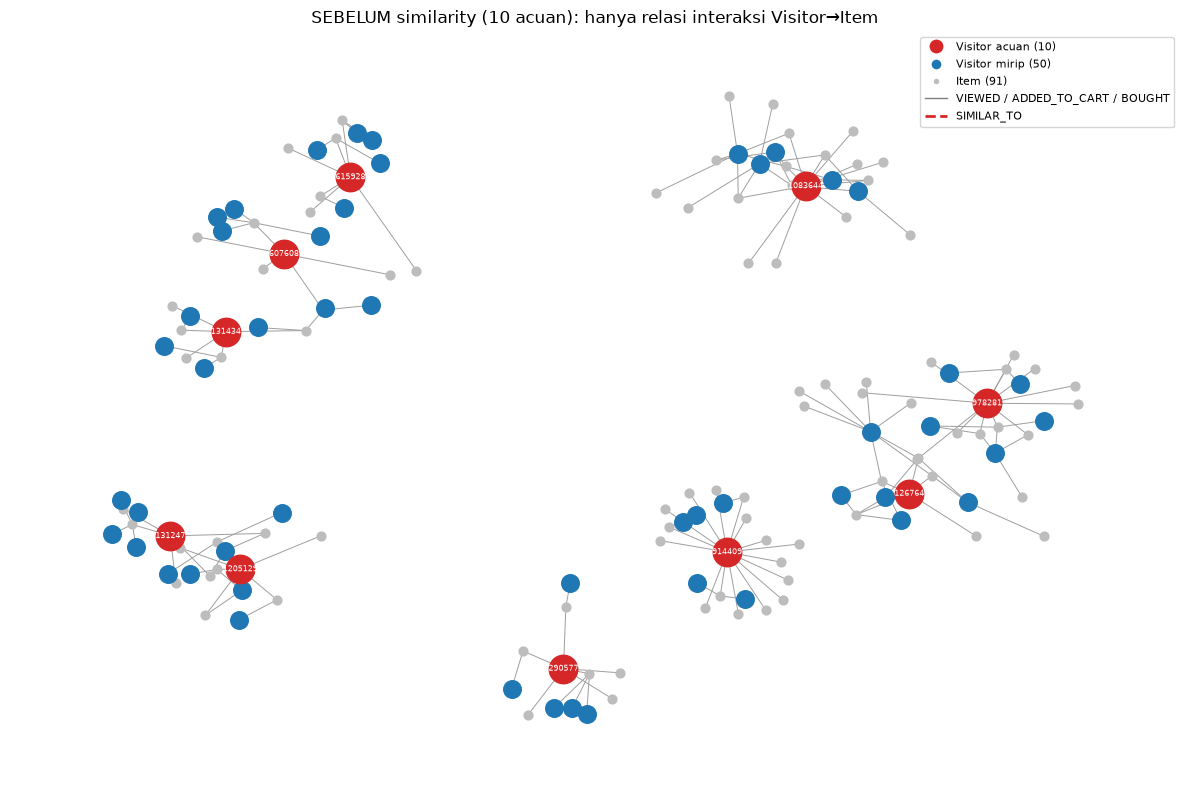

In [75]:
Q_INTERAKSI = """
MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE v.visitorId IN $ids
RETURN DISTINCT v.visitorId AS visitor, i.itemId AS item
"""
Q_SIM_EDGES = """
MATCH (a:Visitor)-[s:SIMILAR_TO]->(b:Visitor)
WHERE a.visitorId IN $ids AND b.visitorId IN $ids
RETURN a.visitorId AS a, b.visitorId AS b, s.similarity AS similarity
"""

anchor_set = set(anchor_ids)
neighbor_set = set(int(x) for x in pairs["visitor_mirip"]) - anchor_set
plot_ids = sorted(anchor_set | neighbor_set)


def gambar_graf(G, pos, judul, figsize=(12, 8)):
    plt.figure(figsize=figsize)
    ax = plt.gca()
    U = lambda v: f"U{v}"
    items = [n for n in G.nodes if n.startswith("I")]
    anc = [U(v) for v in anchor_ids if U(v) in G]
    nbr = [U(v) for v in neighbor_set if U(v) in G]
    nx.draw_networkx_nodes(G, pos, nodelist=items, node_color="#bdbdbd", node_size=40, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=nbr, node_color="#1f77b4", node_size=160, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=anc, node_color="#d62728", node_size=420, ax=ax)
    e_int = [(u, v) for u, v, d in G.edges(data=True) if d["tipe"] == "interaksi"]
    e_sim = [(u, v) for u, v, d in G.edges(data=True) if d["tipe"] == "similar"]
    nx.draw_networkx_edges(G, pos, edgelist=e_int, edge_color="#9e9e9e", width=0.7, arrows=False, ax=ax)
    if e_sim:
        nx.draw_networkx_edges(G, pos, edgelist=e_sim, edge_color="#d62728", width=1.8, style="dashed",
                               arrows=True, arrowsize=10, node_size=160,
                               connectionstyle="arc3,rad=0.08", ax=ax)
        if len(e_sim) <= 30:
            nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{G[u][v]['similarity']:.2f}" for u, v in e_sim},
                                         font_size=6, font_color="#d62728", ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n[1:] for n in anc}, font_size=6, font_color="white", ax=ax)
    ax.legend(handles=[
        Line2D([0], [0], marker="o", color="w", markerfacecolor="#d62728", markersize=11, label=f"Visitor acuan ({len(anc)})"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f77b4", markersize=8,  label=f"Visitor mirip ({len(nbr)})"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="#bdbdbd", markersize=5,  label=f"Item ({len(items)})"),
        Line2D([0], [0], color="gray", lw=1, label="VIEWED / ADDED_TO_CART / BOUGHT"),
        Line2D([0], [0], color="#d62728", lw=2, ls="--", label="SIMILAR_TO"),
    ], loc="best", fontsize=8)
    plt.title(judul); plt.axis("off"); plt.tight_layout(); plt.show()


# ---------- KONDISI SEBELUM ----------
run_query(Q_RESET)
n_sim_sebelum = run_query(Q_COUNT_SIM)[0]["total_relasi_similarity"]
assert n_sim_sebelum == 0, f"Masih ada {n_sim_sebelum} relasi SIMILAR_TO"

inter = pd.DataFrame(run_query(Q_INTERAKSI, ids=plot_ids))
G_before = nx.DiGraph()
for r in inter.itertuples():
    G_before.add_edge(f"U{r.visitor}", f"I{r.item}", tipe="interaksi")
for v in plot_ids:
    G_before.add_node(f"U{v}")

G_pos = G_before.copy()
G_pos.add_edges_from((f"U{a}", f"U{b}") for a, b in zip(pairs["visitor_acuan"], pairs["visitor_mirip"]))
pos = nx.spring_layout(G_pos.to_undirected(), seed=SEED, k=0.6, iterations=200)

print("Jumlah SIMILAR_TO SEBELUM:", n_sim_sebelum)
print(f"Graf sebelum: {G_before.number_of_nodes()} simpul, {G_before.number_of_edges()} sisi")
gambar_graf(G_before, pos, f"SEBELUM similarity ({len(anchor_ids)} acuan): hanya relasi interaksi Visitor→Item")

Jumlah SIMILAR_TO SESUDAH: 50


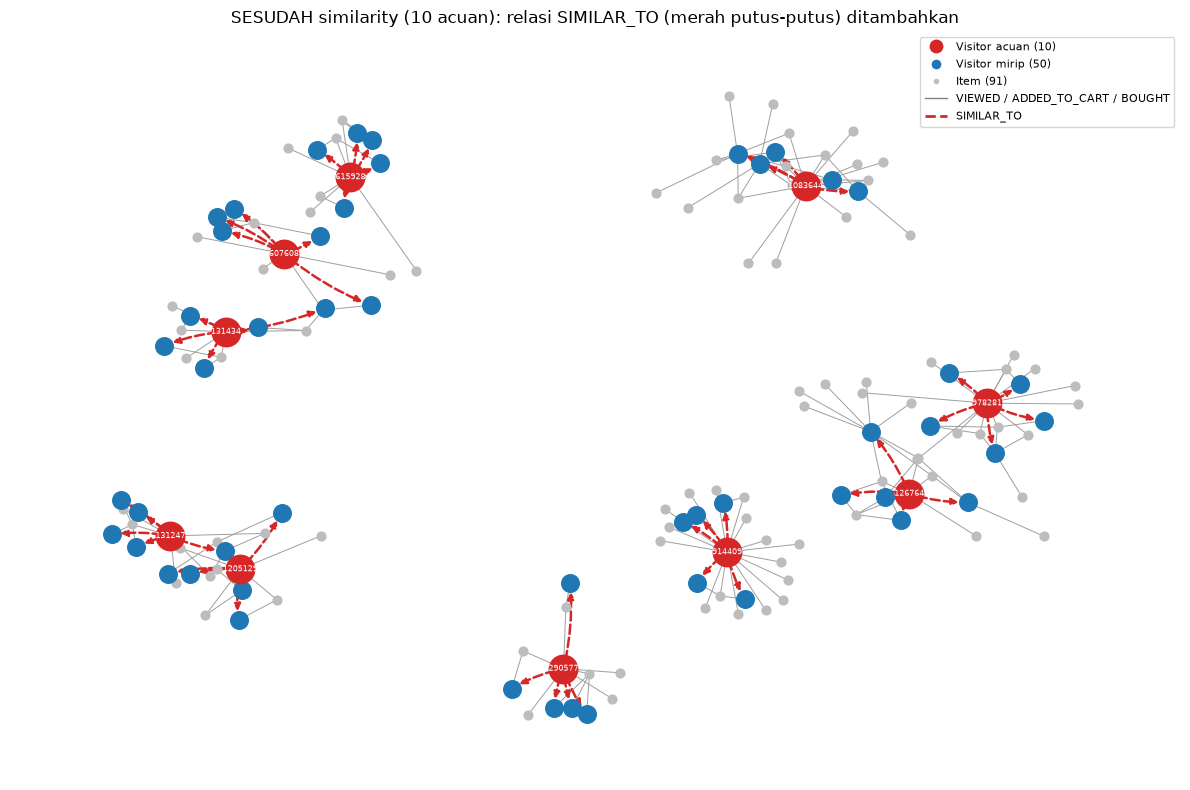

,kondisi,relasi SIMILAR_TO,simpul,sisi
0,Sebelum,0,151,160
1,Sesudah,50,151,210


,count,mean,std,min,25%,50%,75%,max
statistik similarity,50.0,0.416949,0.095467,0.25,0.408248,0.408248,0.447214,0.632456


In [76]:
hasil_tulis = jalankan_batch(Q_TULIS_BANYAK, anchor_ids)
n_sim_sesudah = run_query(Q_COUNT_SIM)[0]["total_relasi_similarity"]
assert n_sim_sesudah == len(pairs), f"Tertulis {n_sim_sesudah}, seharusnya {len(pairs)}"

cek = pairs.merge(hasil_tulis, on=["visitor_acuan", "visitor_mirip"], suffixes=("_hitung", "_graf"), how="outer")
assert cek[["similarity_hitung", "similarity_graf"]].notna().all().all()
assert np.allclose(cek["similarity_hitung"], cek["similarity_graf"], atol=1e-6)

sim_edges = pd.DataFrame(run_query(Q_SIM_EDGES, ids=plot_ids))
G_after = G_before.copy()
for r in sim_edges.itertuples():
    G_after.add_edge(f"U{r.a}", f"U{r.b}", tipe="similar", similarity=float(r.similarity))

print("Jumlah SIMILAR_TO SESUDAH:", n_sim_sesudah)
gambar_graf(G_after, pos, f"SESUDAH similarity ({len(anchor_ids)} acuan): relasi SIMILAR_TO (merah putus-putus) ditambahkan")

display(pd.DataFrame({
    "kondisi": ["Sebelum", "Sesudah"],
    "relasi SIMILAR_TO": [n_sim_sebelum, n_sim_sesudah],
    "simpul": [G_before.number_of_nodes(), G_after.number_of_nodes()],
    "sisi": [G_before.number_of_edges(), G_after.number_of_edges()],
}))
display(sim_edges["similarity"].describe().to_frame("statistik similarity").T)

In [77]:
ids_txt = ", ".join(str(i) for i in plot_ids)

q_before = f"""MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
WHERE v.visitorId IN [{ids_txt}]
RETURN p;"""

q_after = f"""MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT|SIMILAR_TO]->()
WHERE v.visitorId IN [{ids_txt}]
RETURN p;"""

print("-- SEBELUM --");  print(q_before)
print("\n-- SESUDAH --"); print(q_after)

-- SEBELUM --
MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
WHERE v.visitorId IN [6529, 11563, 12940, 14950, 15881, 21343, 22629, 27213, 34139, 37976, 44894, 48435, 55484, 56279, 58291, 58740, 63231, 69794, 75857, 81575, 82243, 97691, 104862, 105020, 123677, 126764, 131247, 131434, 145157, 149870, 153288, 153792, 175298, 195306, 195395, 198542, 199927, 221233, 231470, 237653, 249639, 254701, 290577, 290581, 364589, 411032, 607608, 612577, 615928, 698033, 914409, 928411, 967353, 978281, 1083644, 1194340, 1205129, 1256617, 1259528, 1320953]
RETURN p;

-- SESUDAH --
MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT|SIMILAR_TO]->()
WHERE v.visitorId IN [6529, 11563, 12940, 14950, 15881, 21343, 22629, 27213, 34139, 37976, 44894, 48435, 55484, 56279, 58291, 58740, 63231, 69794, 75857, 81575, 82243, 97691, 104862, 105020, 123677, 126764, 131247, 131434, 145157, 149870, 153288, 153792, 175298, 195306, 195395, 198542, 199927, 221233, 231470, 237653, 249639, 254701, 290577, 290

### Penjelasan 2.1 No.8 Hasil visualisasi graph sebelum dan sesudah similarity
Pada kondisi sebelum perhitungan similarity, visitor acuan dan visitor mirip hanya terhubung secara tidak langsung melalui item yang sama (pola Visitor–Item–Visitor), sehingga visitor mirip berada di ujung cabang klaster. Setelah relasi SIMILAR_TO ditulis, setiap visitor acuan terhubung langsung ke lima tetangga terdekatnya sehingga graf membentuk pola bintang yang lebih padat. Jumlah klaster, simpul, dan relasi interaksi tidak berubah; yang bertambah hanyalah relasi SIMILAR_TO berbobot. Dengan demikian, similarity mengubah kedekatan yang tersirat menjadi relasi eksplisit yang dapat langsung dipakai untuk pencarian tetangga terdekat pada sistem rekomendasi.

## 2.2 Analytics

### 1 Analytics Sistem Rekomendasi

In [40]:
MIN_P1 = 5
user_pos = pd.Series(np.arange(len(visitor_ids)), index=visitor_ids)
test_sets = test.groupby("visitorid")["itemid"].agg(set)
item_set = set(item_ids.tolist())

relevant_by_user = {}
for u, items in test_sets.items():
    pos = user_pos.get(u)
    if pos is None or nnz_user[pos] < MIN_P1:
        continue
    seen = set(item_ids[Mu.indices[Mu.indptr[pos]:Mu.indptr[pos + 1]]].tolist())
    rel = (set(items) & item_set) - seen
    if rel:
        relevant_by_user[int(u)] = rel
print("Ukuran kolam user:", len(relevant_by_user))

target_user = int(np.random.default_rng(SEED).choice(sorted(relevant_by_user)))
target_idx = int(user_pos[target_user])
relevant_items = relevant_by_user[target_user]
print(f"Seed={SEED} | user acuan={target_user} | item di P1={nnz_user[target_idx]} | item relevan di P2={len(relevant_items)}")

Ukuran kolam user: 1153
Seed=42 | user acuan=137360 | item di P1=6 | item relevan di P2=1


In [41]:
def recommend(user_idx, k=K, n=TOP_N):
    sims = (Mu_norm[user_idx] @ Mu_norm.T).toarray().ravel()
    sims[user_idx] = -1.0
    cand = np.flatnonzero(sims > 0)
    nbr = cand[np.argsort(-sims[cand], kind="stable")[:k]]
    item_scores = np.asarray(Mu[nbr].T.dot(sims[nbr])).ravel()
    item_scores[Mu.indices[Mu.indptr[user_idx]:Mu.indptr[user_idx + 1]]] = 0.0     # buang item yang sudah dilihat
    top = [j for j in np.argsort(-item_scores, kind="stable")[:n] if item_scores[j] > 0]
    return nbr, sims[nbr], top, item_scores[top]


nbr, nbr_sims, top, top_scores = recommend(target_idx)
neighbors_df = pd.DataFrame({"visitorid": visitor_ids[nbr], "similarity": nbr_sims})
print(f"(a) K = {K} tetangga terdekat dari user {target_user}:")
display(neighbors_df)

recs = pd.DataFrame({"rank": range(1, len(top) + 1), "itemid": item_ids[top], "score": top_scores})
recs["relevan_di_P2"] = recs["itemid"].isin(relevant_items)
print("Daftar rekomendasi top-5:")
display(recs)
print("(b) 3 item yang diiklankan untuk k = 5:")
display(recs.head(3)[["rank", "itemid", "score"]])

(a) K = 5 tetangga terdekat dari user 137360:


,visitorid,similarity
0,46195,0.408248
1,69445,0.408248
2,93681,0.408248
3,100078,0.408248
4,115912,0.408248


Daftar rekomendasi top-5:


,rank,itemid,score,relevan_di_P2


(b) 3 item yang diiklankan untuk k = 5:


,rank,itemid,score


### Penjelasan 2.2 No.1 Sistem rekomendasi
Output ini menunjukkan bahwa sistem berhasil menemukan 5 tetangga terdekat untuk user 137360 yaitu 46195 69445 93681 100078 dan 115912. Kelima tetangga punya nilai similarity yang sama yaitu 0,408248 atau setara 1/√6 sehingga kemiripannya seri. Kemiripan itu kemungkinan berasal dari satu item yang sama dengan user acuan.

Daftar rekomendasi top-5 dan tabel 3 item iklan hanya menampilkan header kolom tanpa isi. Artinya belum ada item yang direkomendasikan. Penyebab yang mungkin adalah item milik tetangga sudah dimiliki user acuan di P1 sehingga tidak ada kandidat baru. Penyebab lain adalah kesalahan pada kode penggabungan skor atau filter.

Karena itu hasil rekomendasi belum bisa dievaluasi terhadap 1 item relevan di P2.

### 2 Analytics Menghitung Hit@5 dan NDCG@5

In [42]:
def hit_ndcg(recommended, relevant, n=TOP_N):
    rels = [1 if x in relevant else 0 for x in recommended[:n]]
    hit = float(any(rels))
    dcg = sum(r / np.log2(i + 2) for i, r in enumerate(rels))
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), n)))
    return hit, (dcg / idcg if idcg > 0 else 0.0)


hit5, ndcg5 = hit_ndcg(recs["itemid"].tolist(), relevant_items)
print(f"User acuan      : {target_user}")
print(f"Item relevan P2 : {sorted(relevant_items)[:10]}{' ...' if len(relevant_items) > 10 else ''} (total {len(relevant_items)})")
print(f"Top-5           : {recs['itemid'].tolist()}")
print(f"Hit@5           : {hit5:.0f}")
print(f"NDCG@5          : {ndcg5:.4f}")

User acuan      : 137360
Item relevan P2 : [64747] (total 1)
Top-5           : []
Hit@5           : 0
NDCG@5          : 0.0000


### Penjelasan 2.2 No.2 Penjelasan Hit@5 dan NDCG@5

Berdasarkan hasil rekomendasi pada bagian 1b Analytics, evaluasi dilakukan terhadap user acuan 137360 yang memiliki satu item relevan pada periode P2 yaitu item 64747. Daftar Top-5 yang dihasilkan sistem ternyata kosong sehingga item relevan tersebut tidak muncul dalam rekomendasi.

Kondisi ini membuat nilai Hit@5 sebesar 0 karena metrik tersebut hanya bernilai 1 apabila minimal satu item relevan terdapat di antara lima rekomendasi teratas. Nilai NDCG@5 juga sebesar 0,0000 karena DCG@5 bernilai 0 akibat tidak adanya item relevan yang terambil sedangkan IDCG@5 bernilai 1 untuk kondisi ideal dengan satu item relevan berada di posisi pertama. Dengan demikian NDCG@5 diperoleh dari 0 dibagi 1 yaitu 0.

Hasil ini tidak berarti sistem salah menebak item melainkan sistem belum menghasilkan rekomendasi sama sekali. Hal tersebut kemungkinan disebabkan oleh kelima tetangga terdekat yang hanya memiliki sedikit interaksi dan seluruh item miliknya sudah terdapat pada riwayat user acuan di P1 sehingga tidak tersisa kandidat item baru. Apabila item 64747 berhasil muncul di posisi pertama maka Hit@5 akan bernilai 1 dan NDCG@5 juga bernilai 1.